# Convolutional Digit Classifier

Two convolutional layers learn local stroke features directly from the original eight-pixel-wide digits.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Network

Pooling reduces the spatial size once. The final linear layer receives all remaining locations.

In [2]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import digits_split, class_scores, confusion
from gallery.neural import seed_cpu, train_classifier


def digit_net():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1),
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(32 * 4 * 4, 10),
    )

## Fit and evaluate

The epoch count is fixed. The held-out split is used once for the reported classification scores.

Accuracy 0.980 | Balanced accuracy 0.980 | MCC 0.978
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.958     1.000     0.979        46
           2      1.000     0.977     0.989        44
           3      0.958     1.000     0.979        46
           4      0.957     1.000     0.978        45
           5      1.000     0.978     0.989        46
           6      0.978     1.000     0.989        45
           7      0.978     0.978     0.978        45
           8      1.000     0.907     0.951        43
           9      0.977     0.956     0.966        45

    accuracy                          0.980       450
   macro avg      0.981     0.980     0.980       450
weighted avg      0.981     0.980     0.980       450

Log loss 0.076 | Macro ROC AUC (one-vs-rest) 1.000
Macro average precision 0.997 | Multiclass Brier 0.035


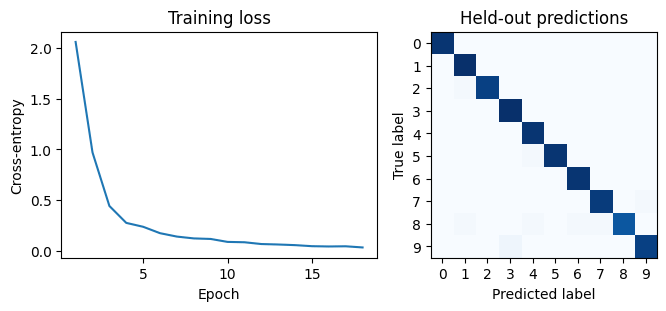

In [3]:
seed_cpu()
train, test, y, y_test = digits_split()
net = digit_net()
loss = train_classifier(net, train[:, None], y, epochs=18)
with torch.no_grad():
    prob = net(torch.tensor(test[:, None])).softmax(1).numpy()
pred = prob.argmax(1)
class_scores(y_test, pred, prob)
fig, (a, b) = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
a.plot(range(1, len(loss) + 1), loss)
a.set(xlabel="Epoch", ylabel="Cross-entropy", title="Training loss")
confusion(b, y_test, pred)
plt.show()

## Reading the result

A falling training loss describes optimisation. The confusion matrix identifies which digits remain hard in an independent image split.

## References

[LeCun et al., Gradient-based learning applied to document recognition](https://doi.org/10.1109/5.726791)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Image and video generators and evaluation](../../../gallery/vision.py)